# NB-05 — Protocolo experimental e resultados (Cap. 5)

Compara os motores da plataforma na página **1680-069** do BRESSAY em nove condições de pré-processamento: imagem original, as sete etapas isoladas e todas juntas.

- **Execução:** `nb05_rodar.py` (fora do Jupyter, porque demora e a OpenRouter cobra). Ele usa os motores, o pré-processamento e as métricas da própria plataforma (`lib/protocolo.py`) e grava um JSON por execução em `saidas/NB-05/cache/`.
- **Este notebook** só lê o cache e gera `resultados_finais.csv`, as tabelas `.tex`, as figuras PNG (300 dpi) e o `manifest.json`. Não chama motor nenhum.
- **Métricas:** CER e WER (uma página: o valor global é o da página), cosseno, BERTScore (F1) e juiz (média das três notas).
- **Parâmetros:** os padrões da plataforma em cada motor; nos modelos de linguagem, `max_tokens = 4096` (o padrão, 1024, pode cortar uma página de cerca de 2400 caracteres).

In [1]:
# Parâmetros
from pathlib import Path
IMAGEM = Path.home() / 'text_tcc_unb/unbtex-example/figuras/1680-069.png'
GABARITO = Path.home() / 'text_tcc_unb/unbtex-example/figuras/1680-069.txt'
SAIDA = Path('saidas/NB-05')
SEED = 0  # sem aleatoriedade neste notebook; mantido por convenção

In [2]:
import sys, json, hashlib
sys.path.insert(0, 'lib')
from datetime import datetime
import pandas as pd
from IPython.display import Image, display
import protocolo as P
import protocolo_saidas as S
from benchmark_or import carregar_gabarito

referencia = carregar_gabarito(GABARITO)
registros = P.carregar_cache(SAIDA, referencia)
df = pd.DataFrame([P.linha_plana(r) for r in registros])
print('gabarito:', len(referencia), 'caracteres,', len(referencia.split()), 'palavras')
print(len(df), 'execuções em cache;', df.motor.nunique(), 'motores/modelos;', df.condicao.nunique(), 'condições')

gabarito: 2394 caracteres, 381 palavras
121 execuções em cache; 14 motores/modelos; 9 condições


## 1. Cobertura da matriz
O que falta aparece como `NaN`: motor indisponível na hora da execução (a VM da GPU, por exemplo) ou erro do modelo.

In [3]:
cobertura = df.pivot(index='motor', columns='condicao', values='cer').reindex(columns=list(P.CONDICOES))
faltam = int(cobertura.isna().sum().sum())
print('células sem resultado:', faltam)
print('sem BERTScore:', int(df.bertscore_f1.isna().sum()), '| sem juiz:', int(df.juiz_media.isna().sum()))
cobertura.round(3)

células sem resultado: 5
sem BERTScore: 9 | sem juiz: 9


condicao,original,completo,cinza,normalizacao,ruido,deskew,binarizacao,ampliacao,nitidez
motor,,,,,,,,,
EasyOCR,0.615,0.699,0.615,0.613,0.636,0.615,0.630,0.649,0.621
Ollama|deepseek-ocr:latest,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
Ollama|glm-ocr:q8_0,2.354,0.988,2.376,2.557,2.356,2.467,2.309,0.986,2.517
Ollama|llava:latest,0.973,0.973,0.886,0.973,0.973,0.886,0.973,0.973,0.973
Ollama|richardyoung/olmocr2:7b-q8,0.018,NaN,0.018,0.018,0.022,0.018,0.020,NaN,0.018
OpenRouter|anthropic/claude-haiku-5.5,0.009,0.024,0.009,0.012,0.014,0.009,0.013,0.008,0.014
OpenRouter|anthropic/claude-sonnet-5.5,0.005,0.013,0.005,0.007,0.004,0.007,0.010,0.005,0.009
OpenRouter|google/gemini-2.5-flash,0.011,0.014,0.011,0.012,0.013,0.011,0.019,0.010,0.013
OpenRouter|google/gemini-3.8-flash,0.031,0.006,0.009,0.008,0.008,0.026,0.003,0.025,0.026


## 2. Motores na imagem original

In [4]:
orig = df[df.condicao == 'original'].sort_values('cer')
cols = ['motor', 'cer', 'wer', 'cosseno', 'bertscore_f1', 'juiz_media', 'tempo_ms', 'custo_usd', 'dispositivo', 'execucao', 'data']
orig[cols].round(4)

,motor,cer,wer,cosseno,bertscore_f1,juiz_media,tempo_ms,custo_usd,dispositivo,execucao,data
52,OpenRouter|anthropic/claude-sonnet-5.5,0.0050,0.0472,0.9994,0.9949,5.00,5522.6083,0.0131,CPU,Local,2026-11-15T12:55:30
43,OpenRouter|anthropic/claude-haiku-5.5,0.0088,0.0525,0.9926,0.9781,5.00,8777.6737,0.0014,CPU,Local,2026-11-15T12:53:55
106,OpenRouter|z-ai/glm-5.3-flash,0.0092,0.0472,0.9932,0.9775,5.00,29273.9518,0.0017,CPU,Local,2026-11-15T13:08:04
88,OpenRouter|openai/gpt-6-luna,0.0096,0.0525,0.9926,0.9759,5.00,18260.0371,0.0011,CPU,Local,2026-11-15T12:56:53
61,OpenRouter|google/gemini-2.5-flash,0.0109,0.0315,0.9961,0.9894,5.00,2988.7417,0.0015,CPU,Local,2026-11-15T12:53:02
97,OpenRouter|qwen/qwen3-vl-235b-a22b-instruct,0.0167,0.0604,0.9895,0.9725,5.00,22975.0088,0.0015,CPU,Local,2026-11-15T13:00:44
36,Ollama|richardyoung/olmocr2:7b-q8,0.0184,0.0761,0.9876,0.9706,4.00,172809.0262,NaN,GPU,Cloud Run,2026-11-15T13:06:08
70,OpenRouter|google/gemini-3.8-flash,0.0313,0.0709,0.9916,0.9644,4.00,17790.4125,0.0109,CPU,Local,2026-11-15T12:51:23
79,OpenRouter|mistralai/mistral-small-3.2-24b-ins...,0.0351,0.0997,0.9851,0.9667,4.00,4822.5767,0.0003,CPU,Local,2026-11-15T13:06:24
112,Tesseract,0.3079,0.7769,0.7114,0.6425,1.67,19828.5414,NaN,CPU,Cloud Run,2026-11-15T12:41:16


## 3. Efeito do pré-processamento
Variação do CER, em pontos percentuais, de cada condição frente à imagem original (negativo = melhora).

In [5]:
delta = (cobertura.drop(columns='original').sub(cobertura['original'], axis=0) * 100).round(2)
display(delta.loc[cobertura['original'].sort_values().index])
print('média por condição (p.p.):'); print(delta.mean().round(2).to_string())

condicao,completo,cinza,normalizacao,ruido,deskew,binarizacao,ampliacao,nitidez
motor,,,,,,,,
OpenRouter|anthropic/claude-sonnet-5.5,0.75,0.04,0.21,-0.08,0.21,0.46,0.04,0.42
OpenRouter|anthropic/claude-haiku-5.5,1.50,0.00,0.33,0.50,0.00,0.42,-0.04,0.50
OpenRouter|z-ai/glm-5.3-flash,3.51,NaN,0.00,0.04,0.84,NaN,0.04,NaN
OpenRouter|openai/gpt-6-luna,47.49,0.13,0.17,0.67,0.08,0.88,-0.08,0.50
OpenRouter|google/gemini-2.5-flash,0.29,0.00,0.08,0.17,0.00,0.79,-0.13,0.21
OpenRouter|qwen/qwen3-vl-235b-a22b-instruct,1.17,0.00,0.08,-0.17,0.00,0.46,-0.29,0.21
Ollama|richardyoung/olmocr2:7b-q8,NaN,0.00,0.00,0.33,0.00,0.21,NaN,-0.04
OpenRouter|google/gemini-3.8-flash,-2.55,-2.26,-2.38,-2.34,-0.50,-2.88,-0.58,-0.50
OpenRouter|mistralai/mistral-small-3.2-24b-instruct,5.76,1.04,-0.42,1.09,-0.42,0.46,-0.88,0.79


média por condição (p.p.):
condicao
completo       -2.97
cinza          -0.59
normalizacao    1.29
ruido           2.25
deskew          0.20
binarizacao     0.08
ampliacao      -9.57
nitidez         1.60


## 4. Arquivos para o texto

['fig_cer_tempo.png', 'fig_cer_wer_original.png', 'fig_efeito_preproc.png', 'tabela_cer_condicoes.tex', 'tabela_resumo.tex', 'tabela_wer_condicoes.tex']


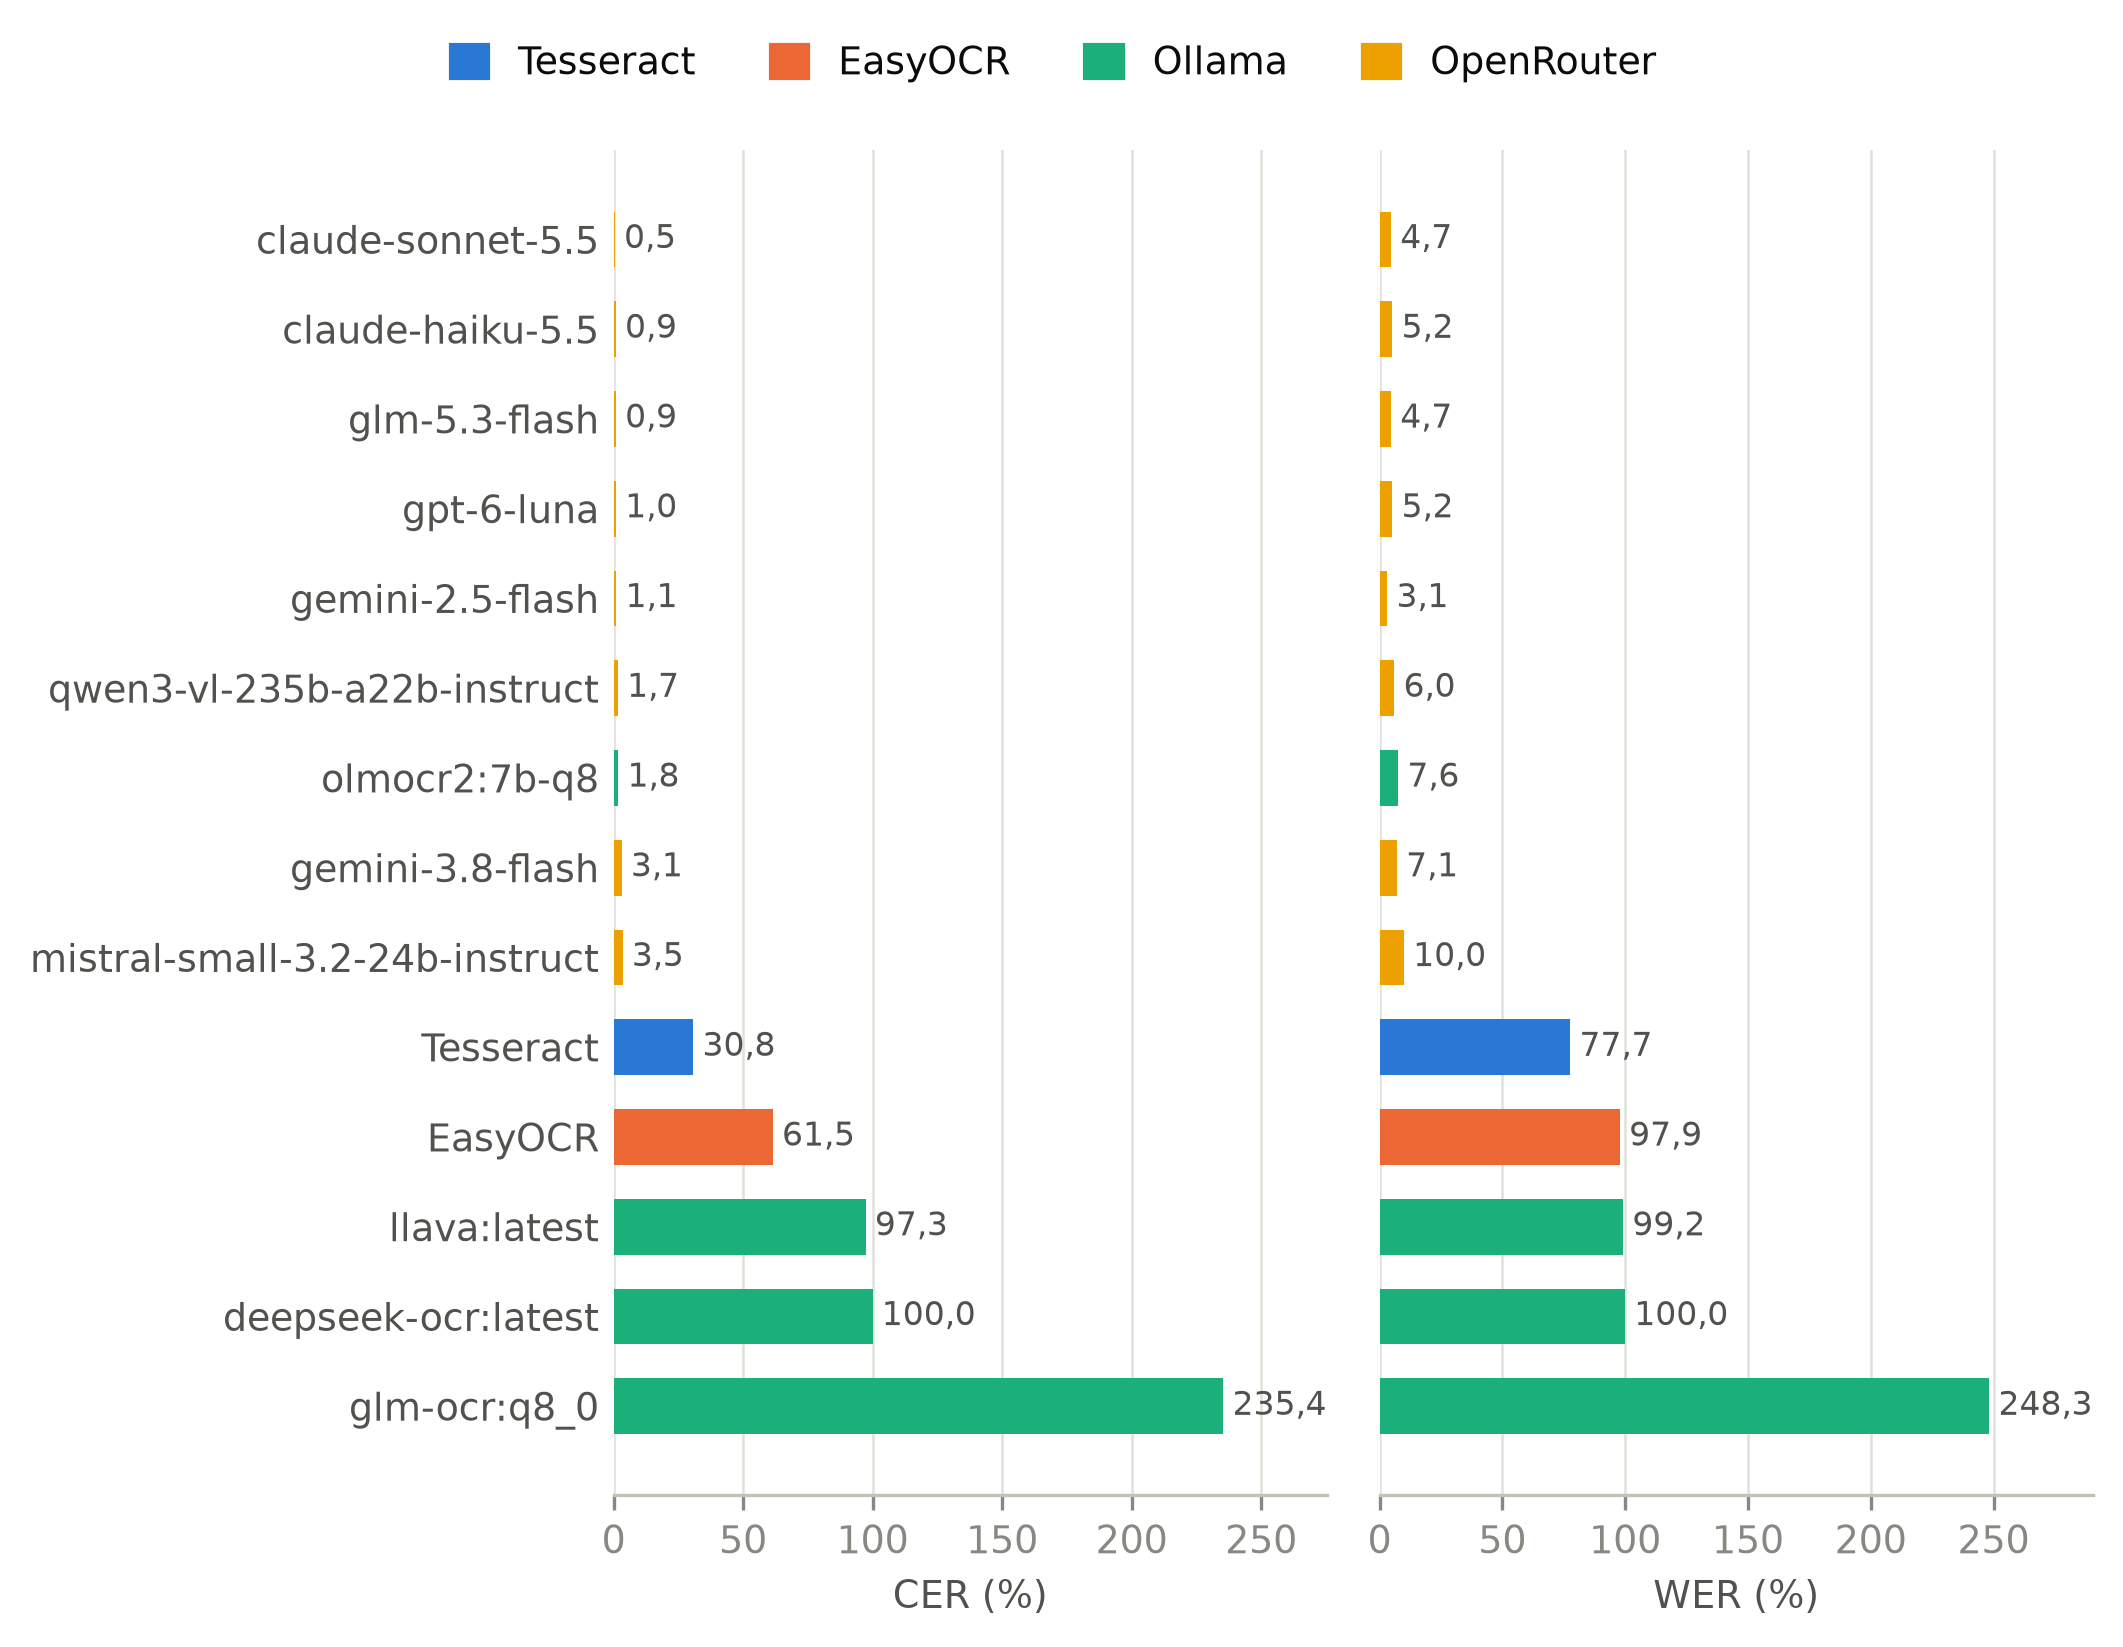

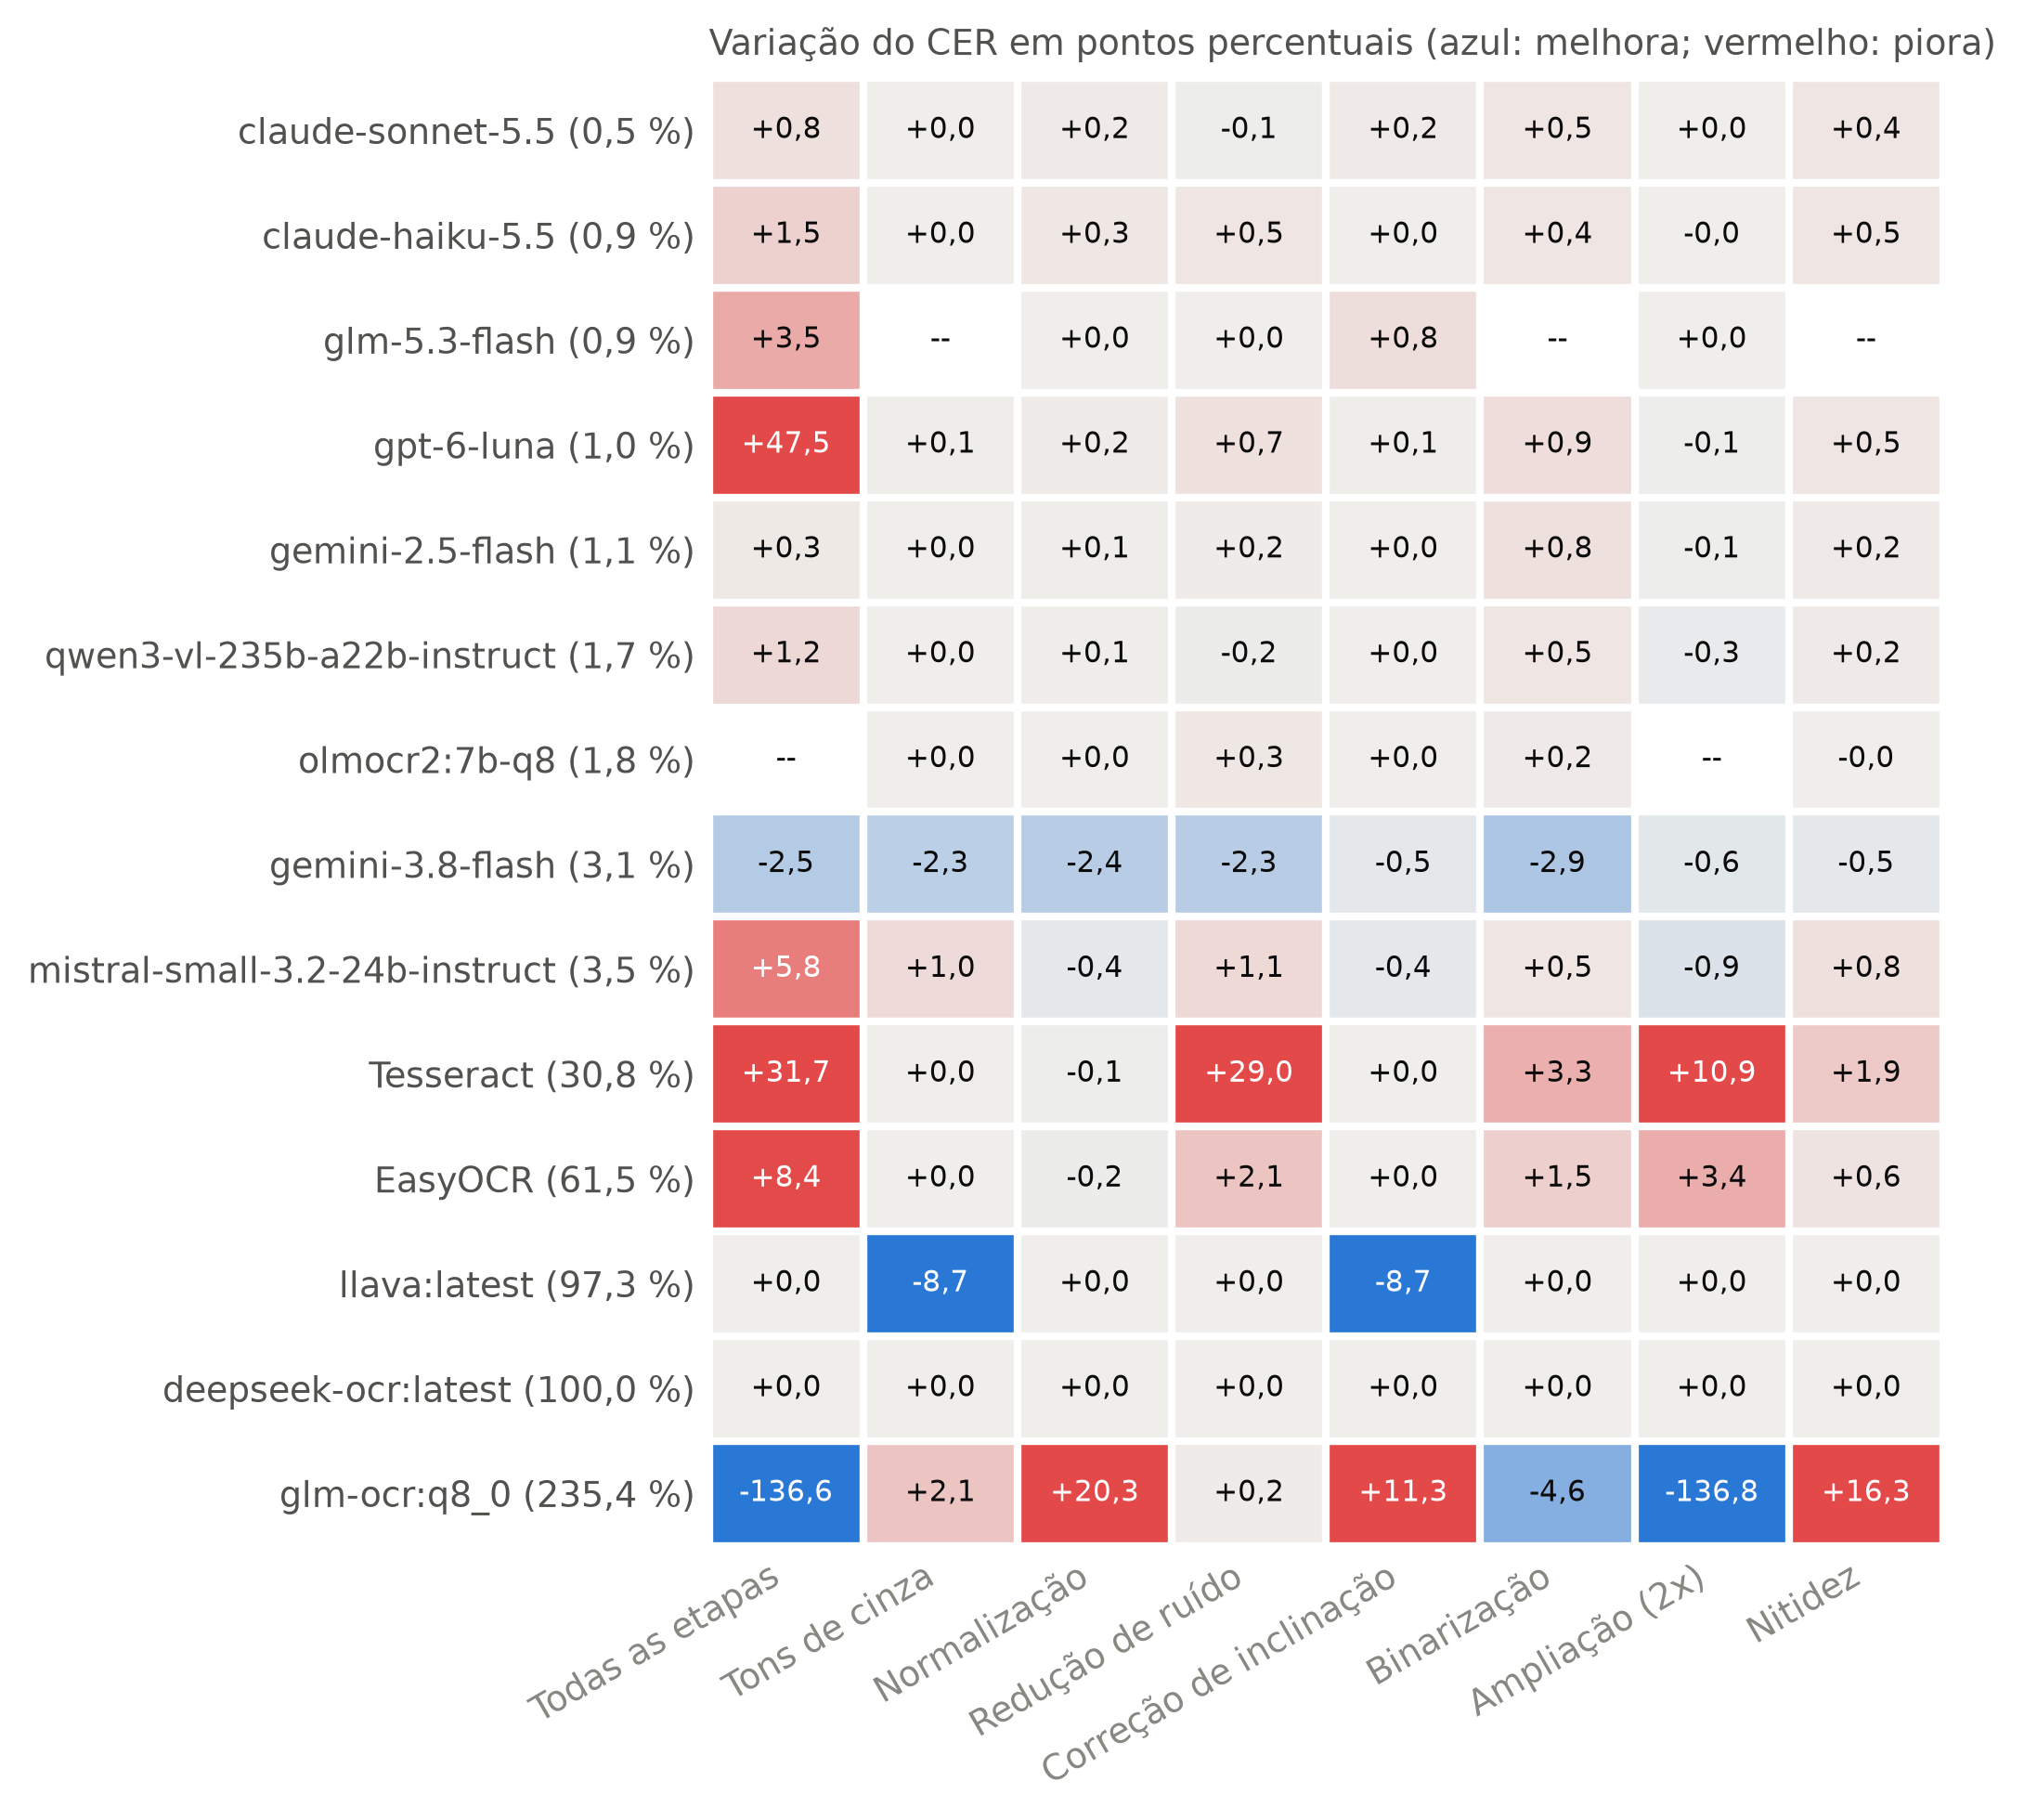

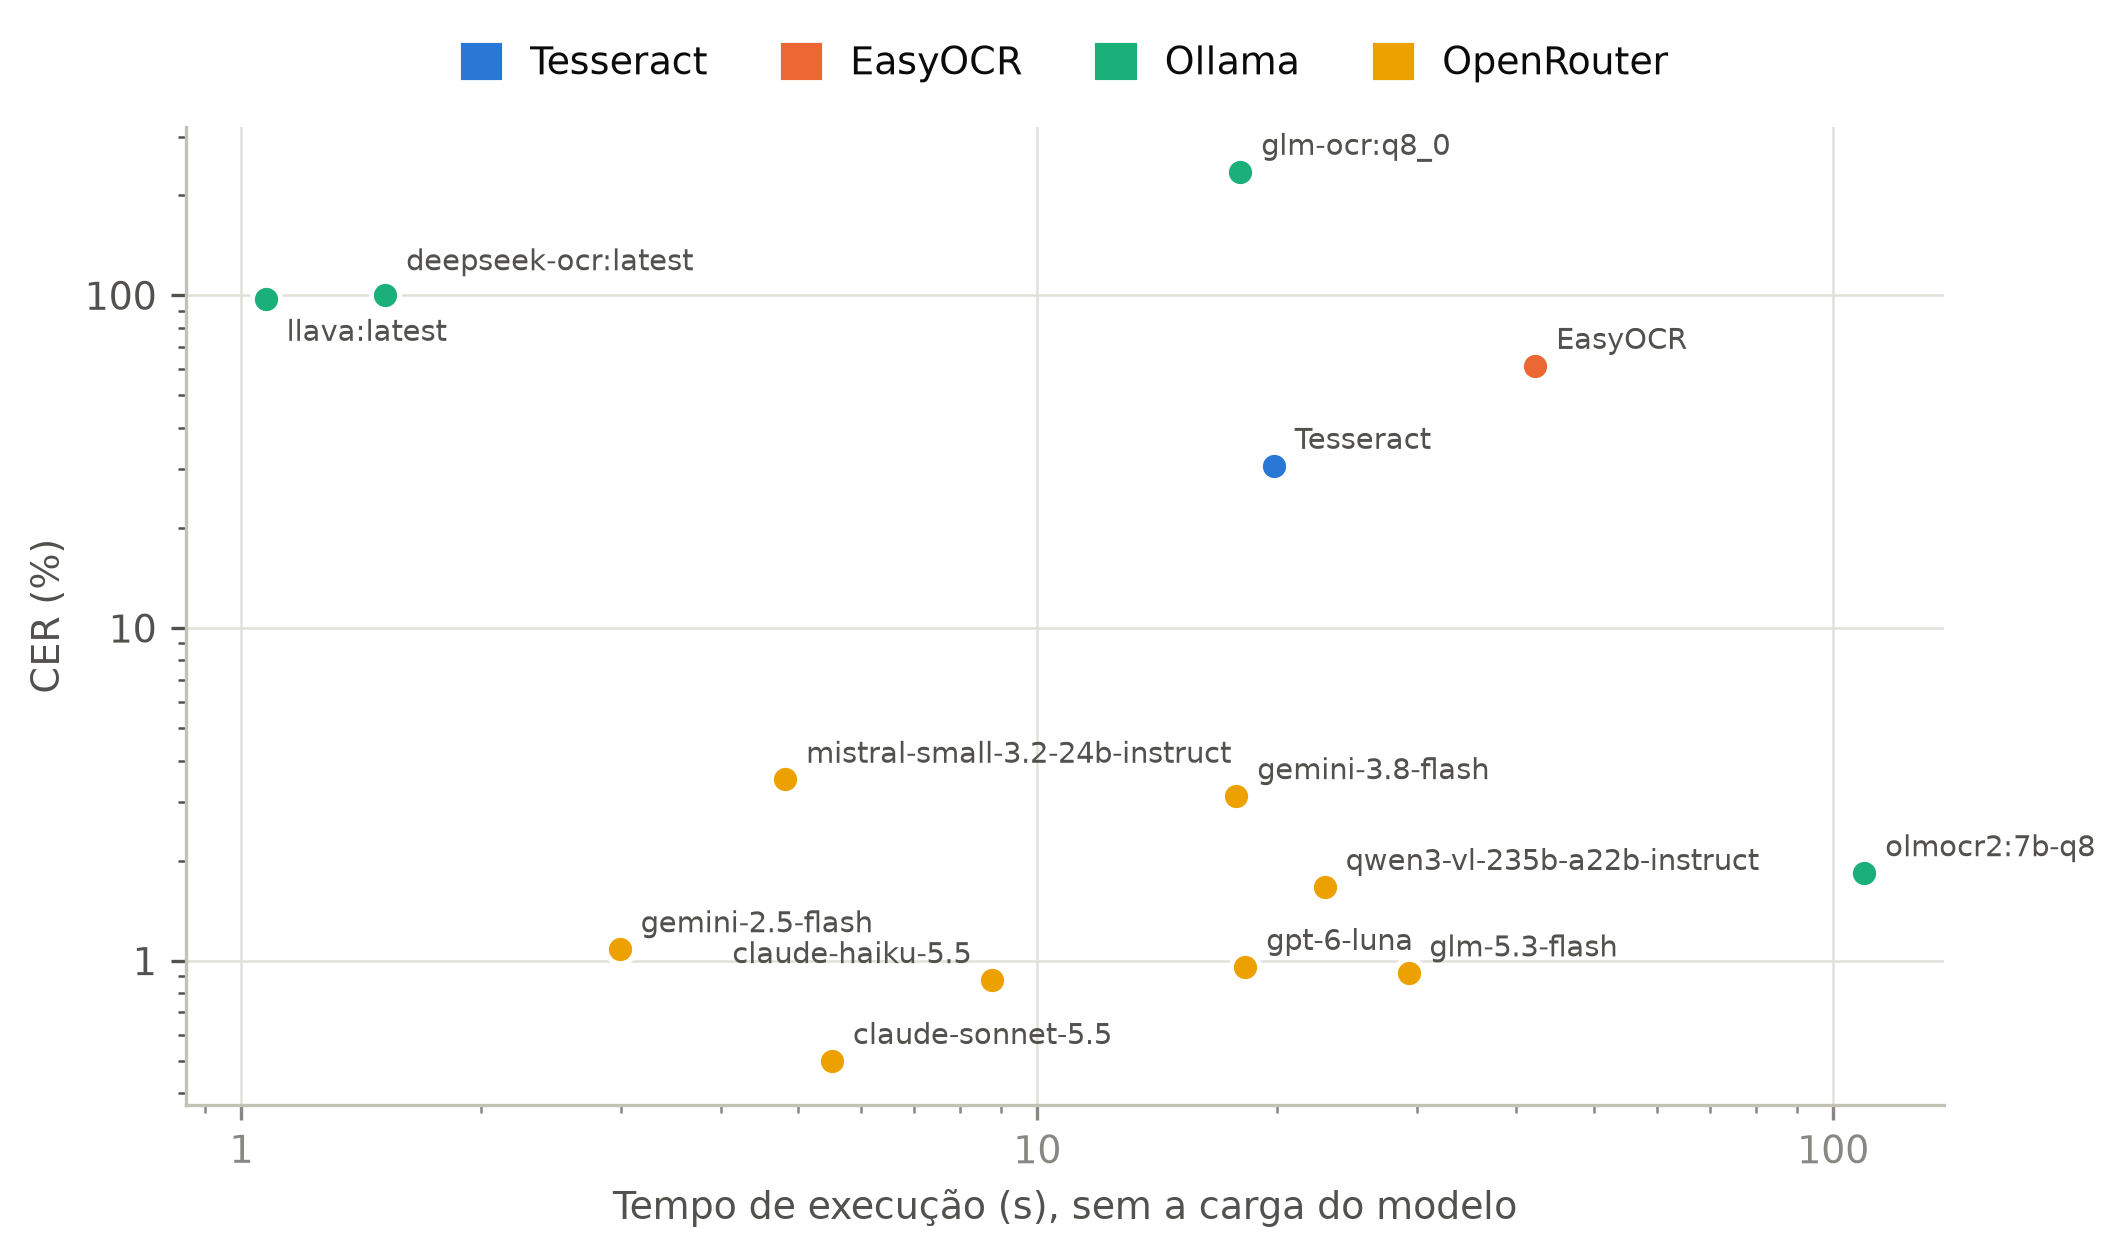

In [6]:
SAIDA.mkdir(parents=True, exist_ok=True)
df.to_csv(SAIDA / 'resultados_finais.csv', index=False)
arquivos = S.gerar(registros, SAIDA)
print(arquivos)
for f in ('fig_cer_wer_original.png', 'fig_efeito_preproc.png', 'fig_cer_tempo.png'):
    display(Image(filename=str(SAIDA / f), width=720))

In [7]:
primeiro = lambda fam: next((r for r in registros if r['familia'] == fam), {})
manifest = {
    'notebook': 'NB-05', 'data': datetime.now().isoformat(timespec='seconds'),
    'imagem': str(IMAGEM), 'imagem_sha256': hashlib.sha256(IMAGEM.read_bytes()).hexdigest(),
    'gabarito_sha256': hashlib.sha256(referencia.encode()).hexdigest(),
    'condicoes': P.CONDICOES,
    'motores': sorted(df.motor.unique()),
    'execucoes': len(df), 'celulas_sem_resultado': faltam,
    'periodo_execucao': [df.data.min(), df.data.max()],
    'custo_total_usd': float(df.custo_usd.fillna(0).sum()),
    'parametros_por_motor': {fam: primeiro(fam).get('params') for fam in sorted(df.familia.unique())},
    'ambiente_por_motor': {fam: primeiro(fam).get('ambiente') for fam in sorted(df.familia.unique())},
    'bertscore_modelo': next((r['bertscore'].get('model') for r in registros if r.get('bertscore')), None),
    'juiz_modelo': next((r['juiz'].get('model') for r in registros if r.get('juiz')), None),
    'arquivos': ['resultados_finais.csv'] + arquivos,
}
(SAIDA / 'manifest.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False))
print(json.dumps({k: v for k, v in manifest.items() if k != 'parametros_por_motor'}, indent=2, ensure_ascii=False))

{
  "notebook": "NB-05",
  "data": "2026-11-15T13:22:49",
  "imagem": "~/text_tcc_unb/unbtex-example/figuras/1680-069.png",
  "imagem_sha256": "8fb2ef3ef1b9f145955295246762ba6a69f69b3d71b9be9683a393f5106c6066",
  "gabarito_sha256": "80d42f8531f986e6a639e6bd384ee4fc369238d4377a6a3fc7f47ba23fe736d0",
  "condicoes": {
    "original": {},
    "completo": {
      "grayscale": true,
      "normalize": true,
      "noise_reduction": true,
      "deskew": true,
      "binarize": true,
      "upscale": true,
      "sharpen": true
    },
    "cinza": {
      "grayscale": true
    },
    "normalizacao": {
      "normalize": true
    },
    "ruido": {
      "noise_reduction": true
    },
    "deskew": {
      "deskew": true
    },
    "binarizacao": {
      "binarize": true
    },
    "ampliacao": {
      "upscale": true
    },
    "nitidez": {
      "sharpen": true
    }
  },
  "motores": [
    "EasyOCR",
    "Ollama|deepseek-ocr:latest",
    "Ollama|glm-ocr:q8_0",
    "Ollama|llava:latest",
    